In [56]:
using LinearAlgebra
using PyPlot
using Trapz
using Calculus

In [108]:
function H_spin(
        energies_up::Array{Float64},
        energies_do::Array{Float64},
        thopping::Array{Float64}
        )
    N = length(energies_up)* 2
    Mtrx = zeros(Float64, N,N)
    for i in 1:2:N
        j = Integer((i +1)/2)
        #diagonaleinträge
        Mtrx[i, i] = energies_up[j]
        Mtrx[i+1, i+1] = energies_do[j] # i+1, i and i, i+1 is empty
        if i<N-2
             #rechte Blockmatrix
            Mtrx[i, i+2] = thopping[1]         #11   
            Mtrx[i, i+3] = thopping[2] # 12
            Mtrx[i+1, i+2] = thopping[3]  #21
            Mtrx[i+1, i+3] = thopping[4]  # 22
            #untere Blockmatrix
            Mtrx[i+2, i] = thopping[1]  # oben links 11
            Mtrx[i+3, i] = thopping[2] # unten link 21
            Mtrx[i+2, i+1] = thopping[3] #12
            Mtrx[i+3, i+1] = thopping[4] #22
        end 
    end
    return Matrix(Mtrx)
end 

H_spin (generic function with 3 methods)

In [153]:
energies_up1 = Array(range(0.2, 1, length = 5))
t_hopping1 = Array([0.1 0. 0. 0.1]) # for hopping matrix order: ( 11, 12, 21, 22)
H1 = H_spin(energies_up1, energies_up1, t_hopping1*1.5)

10×10 Array{Float64,2}:
 0.2   0.0   0.15  0.0   0.0   0.0   0.0   0.0   0.0   0.0
 0.0   0.2   0.0   0.15  0.0   0.0   0.0   0.0   0.0   0.0
 0.15  0.0   0.4   0.0   0.15  0.0   0.0   0.0   0.0   0.0
 0.0   0.15  0.0   0.4   0.0   0.15  0.0   0.0   0.0   0.0
 0.0   0.0   0.15  0.0   0.6   0.0   0.15  0.0   0.0   0.0
 0.0   0.0   0.0   0.15  0.0   0.6   0.0   0.15  0.0   0.0
 0.0   0.0   0.0   0.0   0.15  0.0   0.8   0.0   0.15  0.0
 0.0   0.0   0.0   0.0   0.0   0.15  0.0   0.8   0.0   0.15
 0.0   0.0   0.0   0.0   0.0   0.0   0.15  0.0   1.0   0.0
 0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.15  0.0   1.0

In [119]:
energies_up2 = Array(range(0.2, 1, length= 5))
energies_do2 = Array(range(0.3, 1.1, length = 5))
H2 = H_spin(energies_up2, energies_do2, t_hopping1.*2 )

10×10 Array{Float64,2}:
 0.2  0.0  0.2  0.2  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.3  0.2  0.2  0.0  0.0  0.0  0.0  0.0  0.0
 0.2  0.2  0.4  0.0  0.2  0.2  0.0  0.0  0.0  0.0
 0.2  0.2  0.0  0.5  0.2  0.2  0.0  0.0  0.0  0.0
 0.0  0.0  0.2  0.2  0.6  0.0  0.2  0.2  0.0  0.0
 0.0  0.0  0.2  0.2  0.0  0.7  0.2  0.2  0.0  0.0
 0.0  0.0  0.0  0.0  0.2  0.2  0.8  0.0  0.2  0.2
 0.0  0.0  0.0  0.0  0.2  0.2  0.0  0.9  0.2  0.2
 0.0  0.0  0.0  0.0  0.0  0.0  0.2  0.2  1.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.2  0.2  0.0  1.1

In [129]:
t_hopping2 = Array([0.1 0 0 0.3])
H3 = H_spin(energies_up1, energies_up1, t_hopping2)

10×10 Array{Float64,2}:
 0.2  0.0  0.1  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.2  0.0  0.3  0.0  0.0  0.0  0.0  0.0  0.0
 0.1  0.0  0.4  0.0  0.1  0.0  0.0  0.0  0.0  0.0
 0.0  0.3  0.0  0.4  0.0  0.3  0.0  0.0  0.0  0.0
 0.0  0.0  0.1  0.0  0.6  0.0  0.1  0.0  0.0  0.0
 0.0  0.0  0.0  0.3  0.0  0.6  0.0  0.3  0.0  0.0
 0.0  0.0  0.0  0.0  0.1  0.0  0.8  0.0  0.1  0.0
 0.0  0.0  0.0  0.0  0.0  0.3  0.0  0.8  0.0  0.3
 0.0  0.0  0.0  0.0  0.0  0.0  0.1  0.0  1.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.3  0.0  1.0

In [57]:
function G_und_trans(energy::Float64,
        eta::Float64,
        Hamiltonian::Array{Float64},
        gammas::Array{Float64})
    dim = size(Hamiltonian)[1]
    Matrix_I_e = (energy + eta*1im ) * Matrix(I, dim,dim)

    gamma_l = zeros(Float64, dim,dim)
    gamma_l[1, 1] = gammas[1]
    gamma_l[2,2] = gammas[1]
    # as spin up and spin down sttate of first site are couled to lead? analogue for last of course
    #?!
    gamma_r = zeros(Float64, dim,dim)
    gamma_r[end, end] = gammas[2]
    gamma_r[end-1, end-1] = gammas[2]
    
    matrix_self = -1im *(gamma_l+ gamma_r)/ 2 
    G_ret =  inv(Matrix_I_e - matrix_self - Hamiltonian)
    G_adv = adjoint(G_ret)
    final_Matrix = gamma_l* G_adv * gamma_r * G_ret
    return real.(tr(final_Matrix))
end 

G_und_trans (generic function with 1 method)

[0.107557109910195, 0.10755710991019585, 0.3820550528229664, 0.38205505282296753, 0.6, 0.6000000000000003, 0.8179449471770337, 0.817944947177034, 1.092442890089805, 1.0924428900898053]

sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


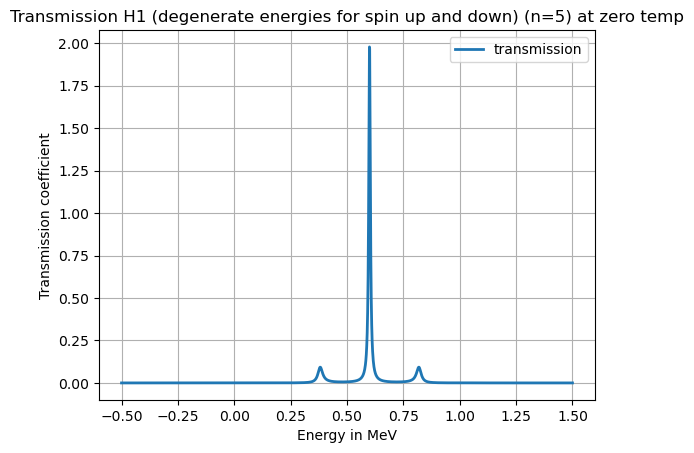

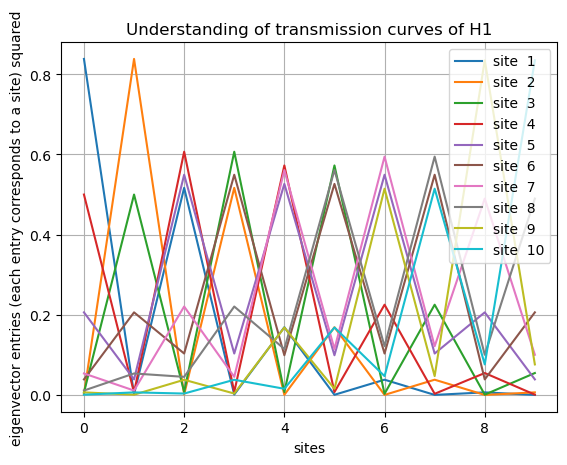

In [154]:

# defining variable for G        
emin, emax = -0.5, 1.5
E_list = Array(range(emin, emax, length = 2000))
eta = 10^(-7)
gammas = Array([.1 .1])

transm_H1 = [G_und_trans(E,eta, H1, gammas) for E in E_list]
plt.figure()
plt.plot(
    E_list, transm_H1,    #mit f. normalerweise komponentenweise
    label = "transmission",
    linewidth = 2 
    )
plt.legend()
#plt.ylim( 0, 0.02)
plt.title("Transmission H1 (degenerate energies for spin up and down) (n=5) at zero temp")
plt.xlabel( "Energy in MeV")
plt.ylabel( "Transmission coefficient")
plt.grid("true")
plt.savefig("transmission_spin_1.pdf")
plt.show()
ei1, vec1 = eigen(H1)
print(ei1)

plt.figure()
for i in range(1, size(vec1)[1], step = 1)
    plt.plot(abs.(vec1[:,i]), label="site  "*string(i))
end
plt.grid("both")
plt.legend()
plt.title( "Understanding of transmission curves of H1")
plt.ylabel("eigenvector entries (each entry corresponds to a site) squared")
plt.xlabel("sites")
plt.savefig("eigen_vec^2_spin_H1.pdf")
plt.show()

### The eigenvalues are not degenerate. Except for one 0.5999 ??????

But 3 eigenvalues have  a really close other eigenvalue. In the Transmission curve, they overlapp for the choosen t and gammas -> looks quiete degenerate

[-0.17908227068581706, 0.2208450782432676, 0.2761038077591751, 0.44754879608505904, 0.6372019912633972, 0.6627980087366032, 0.8524512039149424, 1.0238961922408256, 1.0791549217567327, 1.4790822706858189]

sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


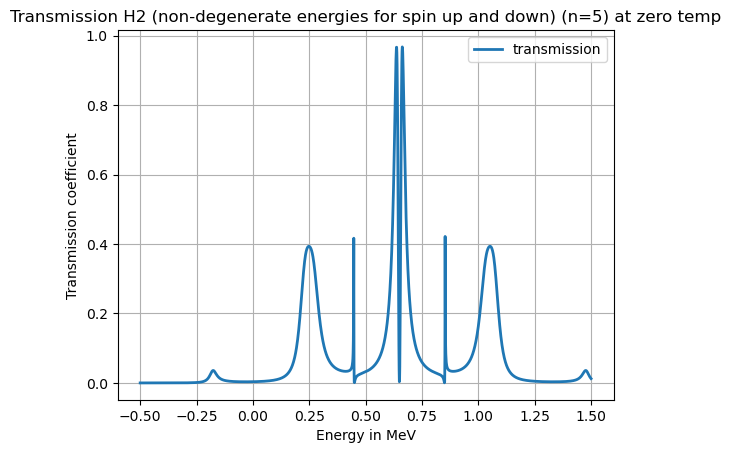

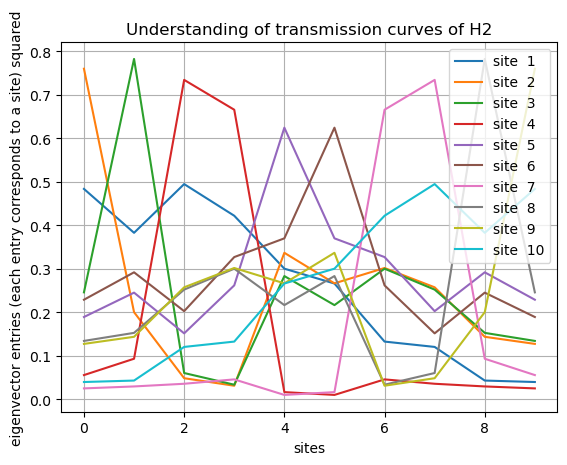

In [120]:
# the same for H2
transm_H2 = [G_und_trans(E,eta, H2, gammas) for E in E_list]
plt.figure()
plt.plot(
    E_list, transm_H2,    #mit f. normalerweise komponentenweise
    label = "transmission",
    linewidth = 2 
    )
plt.legend()
#plt.ylim( 0,0.2* 1e-6)
plt.title("Transmission H2 (non-degenerate energies for spin up and down) (n=5) at zero temp")
plt.xlabel( "Energy in MeV")
plt.ylabel( "Transmission coefficient")
plt.grid("true")
plt.savefig("transmission_spin_2.pdf")
plt.show()
ei2, vec2 = eigen(H2)
print(ei2)

plt.figure()
for i in range(1, size(vec2)[1], step = 1)
    plt.plot(abs.(vec2[:,i]), label="site  "*string(i))
end
plt.grid("both")
plt.legend()
plt.title( "Understanding of transmission curves of H2")
plt.ylabel("eigenvector entries (each entry corresponds to a site) squared")
plt.xlabel("sites")
plt.savefig("eigen_vec^2_spin_H2.pdf")
plt.show()

### The peaks at 0.25 and 1. are also the overlapp of two energy eigenvalues. Here are aswell 3 pairs, where two eigenvalues are close to each other.  

[-0.08006093543810122, 0.15491293350731206, 0.28772268079309216, 0.3953112039193818, 0.5999999999999998, 0.6000000000000001, 0.8046887960806195, 0.9122773192069089, 1.0450870664926875, 1.2800609354381023]

sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


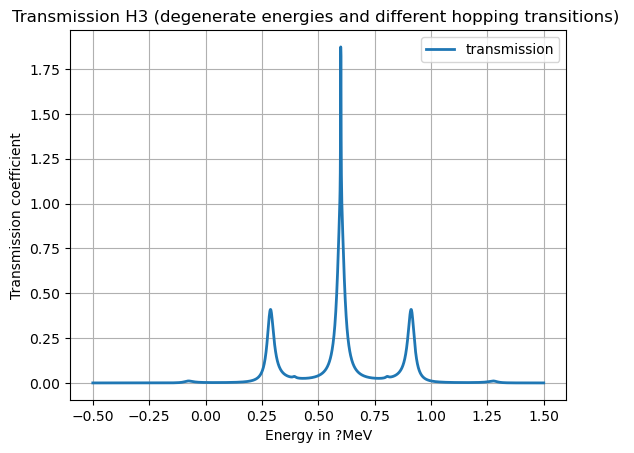

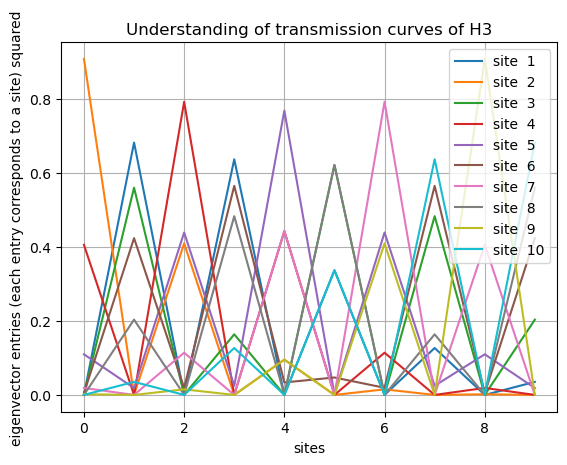

In [130]:
transm_H3 = [G_und_trans(E,eta, H3, gammas) for E in E_list]
plt.figure()
plt.plot(
    E_list, transm_H3,    #mit f. normalerweise komponentenweise
    label = "transmission",
    linewidth = 2 
    )
plt.legend()
#plt.ylim( 0, 0.02)
plt.title("Transmission H3 (degenerate energies and different hopping transitions) ")
plt.xlabel( "Energy in ?MeV")
plt.ylabel( "Transmission coefficient")
plt.grid("true")
plt.savefig("transmission_spin_3.pdf")
plt.show()
ei3, vec3 = eigen(H3)
print(ei3)

plt.figure()
for i in range(1, size(vec3)[1], step = 1)
    plt.plot(abs.(vec3[:,i]), label="site  "*string(i))
end
plt.grid("both")
plt.legend()
plt.title( "Understanding of transmission curves of H3")
plt.ylabel("eigenvector entries (each entry corresponds to a site) squared")
plt.xlabel("sites")
plt.savefig("eigen_vec^2_spin_H3.pdf")
plt.show()

### It is striking, that here the maximal transmission coefficient is above 1.

### It looks quite similar to H1, just that the ratio of the amplitude between middle and outer peaks is here much bigger. The peak positions are nearly the same as for H1.

### 4 smaller mini peaks are here better visible than in the H1 figure

In [92]:
function integral_f(x_data::Array{Float64}, H::Array{Float64},  eta::Float64, gammas::Array{Float64})
    y_int = []
    for i in 1:(length(x_data)-1)
        x_neu  = range(x_data[i], x_data[i+1], length = 10)
        
        y_neu = [G_und_trans(x/ 2,eta, H, gammas) for x in x_neu]
        if i ==1
            push!(y_int, trapz(x_neu, y_neu))
        end
        if i > 1
            s = y_int[i-1] +  trapz(x_neu, y_neu)
            push!(y_int, s)
        end
    end
        plt.plot(x_data[1:end-1], y_int, label= "current")
       
    return y_int
end

integral_f (generic function with 1 method)

sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


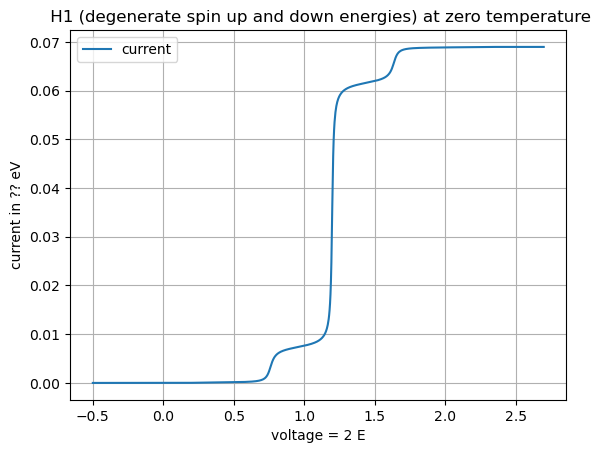

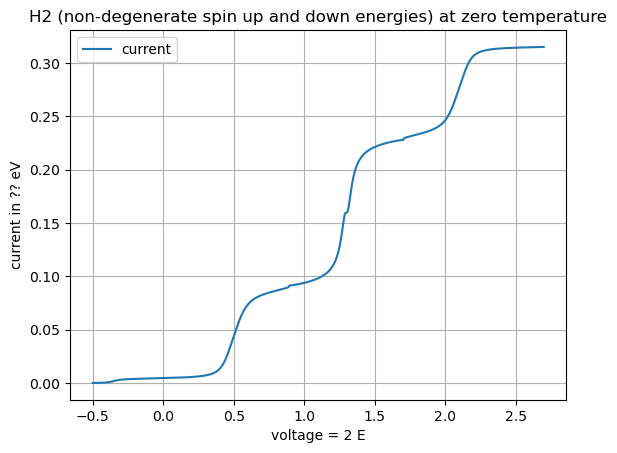

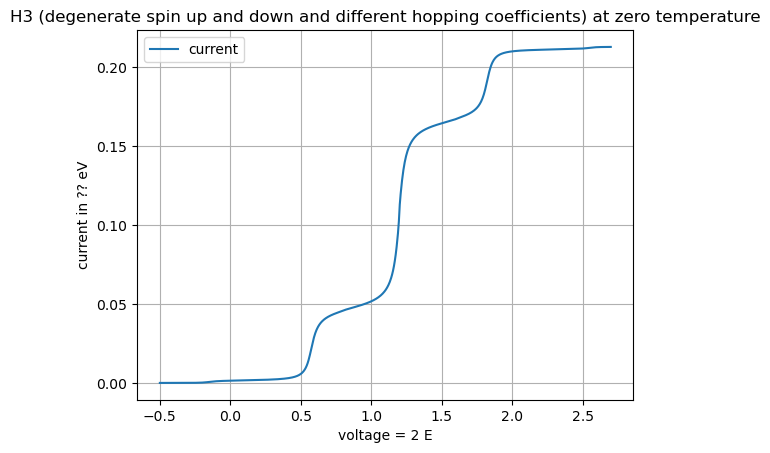

In [155]:
u_list= Array(range(-0.5,2.7, length = 1000))
plt.figure( )
integral_f(u_list, H1,  eta, gammas)
plt.grid( "true")
plt.legend()
plt.xlabel( "voltage = 2 E")
plt.ylabel( "current in ?? eV")
plt.title( " H1 (degenerate spin up and down energies) at zero temperature")
plt.savefig("current_spin_H1.pdf")
plt.show()


plt.figure( )
integral_f(u_list, H2,  eta, gammas)
plt.grid( "true")
plt.legend()
plt.xlabel( "voltage = 2 E")
plt.ylabel( "current in ?? eV")
plt.title( "H2 (non-degenerate spin up and down energies) at zero temperature")
plt.savefig("current_spin_H2.pdf")
plt.show()

plt.figure( )
integral_f(u_list, H3,  eta, gammas)
plt.grid( "true")
plt.legend()
plt.xlabel( "voltage = 2 E")
plt.ylabel( "current in ?? eV")
plt.title( "H3 (degenerate spin up and down and different hopping coefficients) at zero temperature")
plt.savefig("current_spin_H3.pdf")
plt.show()

### Here aswell H1 and H3 look identical. In H2 one can see the thinner and smaller peaks also, but there are 3 outstanding ones only aswell. 
### In H2 the maximal current is greater than for the other Hamiltonians and the spectrum is wider. So the first
### peak is at lower voltage and the highest peak at higher voltage.

# WHY?

In [132]:
function fermi(
        e::Float64,mu_s::Float64, phi_s::Float64, temp_s::Float64)
    return 1/(exp((e- mu_s - phi_s)/temp_s)+ 1) 
end
function to_integrate(
        e::Array{Float64},
        transm::Array{Float64},
        mu_l::Float64, phi_l::Float64, temp_l::Float64, mu_r::Float64, phi_r::Float64, temp_r::Float64 )
    fermi_l = Array([fermi(energy,  mu_l, phi_l, temp_l) for energy in e])
    fermi_r = Array([fermi(energy,  mu_r, phi_r, temp_r) for energy in e] )
    return transm.*(fermi_l .- fermi_r)
end
function integral_f_fermi(
        x_data::Array{Float64}, H::Array{Float64},  eta::Float64, gammas::Array{Float64},
        mu_l::Float64, phi_l::Float64, temp_l::Float64, mu_r::Float64, phi_r::Float64, temp_r::Float64)
    y_int = []
    for i in 1:(length(x_data)-1)
        x_neu  = range(x_data[i], x_data[i+1], length = 10)
        
        trans_neu = [G_und_trans(x/ 2,eta, H, gammas) for x in x_neu]
        y_neu = to_integrate(x_neu./2 , trans_neu,  mu_l, phi_l, temp_l, mu_r, phi_r, temp_r )
        if i ==1
            push!(y_int, trapz(x_neu, y_neu))
        end
        if i > 1
            s = y_int[i-1] +  trapz(x_neu, y_neu)
            push!(y_int, s)
        end
    end
        plt.plot(x_data[1:end-1], y_int, label= "current")
       
    return y_int
end

integral_f_fermi (generic function with 1 method)

sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


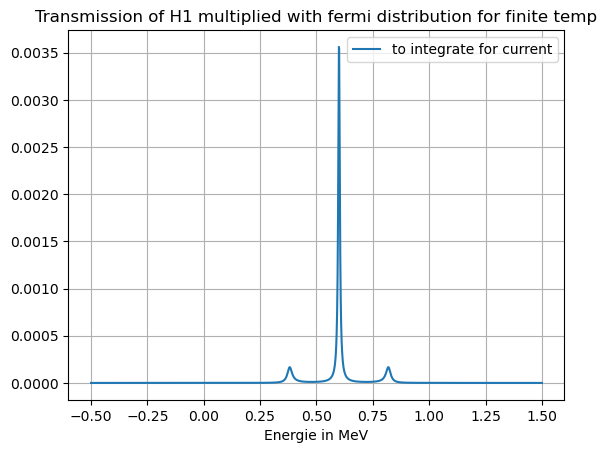

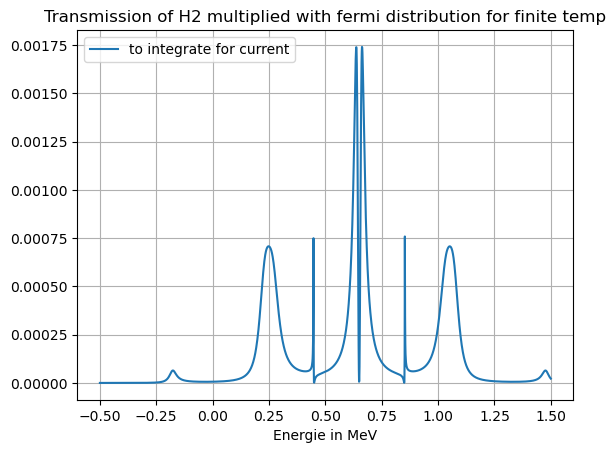

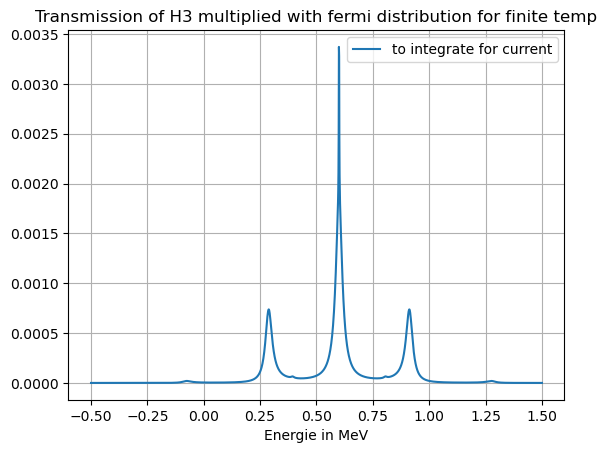

In [156]:
mu_l , phi_l, temp_l = .0, .2, 25.
mu_r, phi_r, temp_r = .0, .02, 25. # wenn die rechte Temp höher ist, wird die differenz der fermi funktionen negativ
# d.h. Kurve ist gespiegelt

plt.figure()
transm_fermi1 = to_integrate( E_list, transm_H1, mu_l , phi_l, temp_l,mu_r, phi_r, temp_r)
plt.plot( E_list,transm_fermi1, 
    label = "to integrate for current"
    )
plt.legend()
plt.title("Transmission of H1 multiplied with fermi distribution for finite temp")
#plt.ylim( -0.01, 0.03)
plt.xlabel("Energie in MeV")
plt.grid("true")
plt.savefig("transm_H1_spin_fermi.pdf")
plt.show()


plt.figure()
transm_fermi2 = to_integrate( E_list, transm_H2, mu_l , phi_l, temp_l,mu_r, phi_r, temp_r)
plt.plot( E_list,transm_fermi2, 
    label = "to integrate for current"
    )
plt.legend()
plt.title("Transmission of H2 multiplied with fermi distribution for finite temp")
#plt.ylim( -0.01, 0.03)
plt.xlabel("Energie in MeV")
plt.grid("true")
plt.savefig("transm_H2_spin_fermi.pdf")
plt.show()

plt.figure()
transm_fermi3 = to_integrate( E_list, transm_H3, mu_l , phi_l, temp_l,mu_r, phi_r, temp_r)
plt.plot( E_list,transm_fermi3 , 
    label = "to integrate for current"
    )
plt.legend()
plt.title("Transmission of H3 multiplied with fermi distribution for finite temp")
#plt.ylim( -0.01, 0.03)
plt.xlabel("Energie in MeV")
plt.grid("true")
plt.savefig("transm_H3_spin_fermi.pdf")
plt.show()

